# Market Echoes: Detecting Global Events in NASDAQ Sector Dynamics (1990–2020)


This notebook presents the **initial analyses and data pipeline** for the project *Market Echoes*.  
It demonstrates that the NASDAQ dataset (1960–2020) can be efficiently handled, explored, and enriched to support the study of market reactions to global events.


---

## 📂 Project Folder Structure

**Root project folder:** `ada-2025-project-missingvalues/`

- `data/` ← Processed or intermediate data files   
  - `symbol_sector_mapping_stocks.csv` ← Created with `yfinance` 
  - `data_raw/`
    - `stocks/`  ← folder which contain CSV files for each stock  
      - `A.csv`  
      - `AA.csv`  
      - ...  
      - `ZYXI.csv`  
    - `etfs/`  ← folder which contain CSV files for each ETFs (not used in this project)  
    - `symbols_valid_meta.csv`  ← Metadata for stocks
- `src/` ← Source code  
  - `data/` ← Loading utilities (`load_function.py`)  
  - `scripts/` ← Preprocessing & enrichment scripts (`preprocess.py`, `create_sector_mapping.py`)  
  - `utils/` ← Helper & plotting functions  
  - `models/` ← Reserved for later milestones  
- `tests/` ← Any unit or integration tests 
- `results.ipynb` ← Main results and preprocessing pipeline  
- `README.md` ← Full project description and methods  
- `pip_requirements.txt` ← Python dependencies  
- `.gitignore` ← Ignore large files and cache


---

## 🧭 Table of Contents

1. [Header & Setup](#header-and-setup)  
2. [Project Context](#project-context)  
3. [Data Loading & Structure Overview](#data-loading--structure-overview)  
4. [Data Quality & Inspection](#data-quality--inspection)  
5. [Data Filtering & Preprocessing](#data-filtering-and-preprocessing)  
6. [Data Enrichment](#data-enrichment-symbolsector-mapping)  
7. [Preliminary Aggregation ](#preliminary-aggregation-feasibility-test)  
8. [Descriptive Checks on Aggregated Data](#descriptive-checks-on-aggregated-data)  
9. [Analytical Roadmap](#analytical-roadmap)  
10. [Discussion & Reproducibility](#discussion--reproducibility)  
11. [References](#references)


## 1. Header & Setup


Execute the following cell to import the required packages and set up the environment.

In [1]:
%pip install -r pip_requirements.txt

Note: you may need to restart the kernel to use updated packages.


This section initializes the notebook environment, loads dependencies,  
and imports all necessary project modules from the `/src/` directory.  

It also defines the visual style and display options for reproducibility.

In [2]:
# === Imports and Setup ===

# Core packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
from tqdm import tqdm 

# Project structure imports
import sys
import os
sys.path.insert(0, os.path.abspath('.'))

# Project modules - data loading and download
from src.data.load_function import load_csv_dataset
from src.data.download_data import download_kaggle_nasdaq

# Project modules - preprocessing
from src.scripts.preprocess import filter_period, add_sector_info, add_columns, aggregate_by_sector, standardize_sector_dict, clean_missing

# Project modules - plotting
from src.utils.plot_fct import plot_sectors, plot_sector_correlation

# Project modules - sector utilities
from src.utils.sector_info import summarize_sector_mapping
from src.scripts.sector_mapping import build_symbol_sector_mapping

# Project modules - saving utilities
from src.utils.save_dataframe import save_dataframe_csv, save_dict_of_dataframes

# Project modules - data quality
from src.scripts.data_quality_inspection import analyze_missing, display_dataset_overview, analyze_correlations, plot_raw_data_overview

# Display options
pd.set_option("display.max_columns", 10)
plt.style.use("seaborn-v0_8")

print("Setup complete")

Setup complete


## 2. Project Context

This notebook is part of the project **Market Echoes: Detecting Global Events in NASDAQ Sector Dynamics (1990 – 2020)**, developed for the EPFL ADA 2025 course.

**Purpose of this notebook**

- Implement and document the complete **data pipeline**, from raw NASDAQ files to a sector-ready dataset.  
- Demonstrate that the dataset can be **loaded, cleaned, enriched, and aggregated** efficiently.  
- Provide initial **feasibility checks** for later event-detection analyses.

**Relation to other project files**

- [`README.md`](./README.md)  → contains the detailed abstract, research questions, and methodological plan.  


## 3. Data Loading & Structure Overview


The complete dataset (~1960 – 2020) contains daily price and volume information for all NASDAQ-listed instruments,  
including both company stocks and ETFs. In this project only the stocks part will be used for analysis.


### Dataset Organization

The raw NASDAQ dataset is organized into two main folders, `/stocks/` and `/etfs/`, each containing one CSV file per ticker.  
Every file represents the daily trading history of a single instrument traded on NASDAQ, and a separate metadata file  
(`symbols_valid_meta.csv`) provides details about tickers .

- **Observation unit:** one instrument (stock or ETF) on a specific trading day  
- **File structure:** individual CSV files for each ticker, plus a metadata CSV  
- **Time coverage:** approximately 1960 – 2020 (coverage may vary by ticker)  
- **Granularity:** daily frequency  
- **Entities:** thousands of unique tickers (≈ 8 000 total; ≈ 5 900 stocks and ≈ 2 100 ETFs)  
- **File format:** CSV, UTF-8 encoded, comma-separated values  

---

### Variable Description

| Variable       | Description                                                    | Unit |
|----------------|----------------------------------------------------------------|------|
| **Date**       | Trading day                                                    | – |
| **Symbol**     | Stock or ETF ticker symbol                                     | – |
| **Open**       | Opening price of the day                                       | USD |
| **high**       | Highest price during the day                                   | USD |
| **Low**        | Lowest price during the day                                    | USD |
| **Close**      | Closing price of the day                                       | USD |
| **Adj close**  | Adjusted closing price (accounts for dividends & splits)       | USD |
| **Volume**     | Number of shares traded during the day                         | shares |



### Download Dataset from Kaggle (Optional)

Use this cell to download and organize the NASDAQ dataset directly into `data/data_raw/`.

**Requirements:**
- Python package: `kagglehub` (install via `pip install kagglehub`)
- Kaggle access set up on this machine

This will place:
- `data/data_raw/stocks/`
- `data/data_raw/etfs/`
- `data/data_raw/symbols_valid_meta.csv`



In [3]:
# Download and organize the NASDAQ dataset to data/data_raw/
from src.data.download_data import download_kaggle_nasdaq
raw_dir = download_kaggle_nasdaq(dest_root="data")

Path to dataset files: C:\Users\danym\.cache\kagglehub\datasets\jacksoncrow\stock-market-dataset\versions\2

Copying selected contents into data\data_raw...
Copying stocks: 

Copying stocks: 100%|██████████| 5884/5884 [00:15<00:00, 369.45it/s]


Copied directory: stocks (5884 files)
Copying etfs: 

Copying etfs: 100%|██████████| 2165/2165 [00:04<00:00, 474.26it/s]

Copied directory: etfs (2165 files)
Copied file: symbols_valid_meta.csv

✓ Dataset successfully organized under: c:\Users\danym\Documents\Dany\EPFL\Cours\MA 1\Applied data analysis\project_ada\ada-2025-project-missingvalues\data\data_raw

Contents of data_raw directory:
  [DIR] etfs/ (2165 files)
  [DIR] stocks/ (5884 files)
  [FILE] symbols_valid_meta.csv


### Data Loading

Load the raw NASDAQ dataset from the local `data/data_raw/` directory.

In [4]:
# Load the raw NASDAQ dataset
symbols_raw, stocks_raw = load_csv_dataset("data/data_raw")

Display dataset statistic

In [5]:
display_dataset_overview(symbols_raw, stocks_raw, total_available=5884, sample_stock='AAPL')


Symbols Metadata:
   • Total symbols: 8,049
   • Columns: ['Nasdaq Traded', 'Symbol', 'Security Name', 'Listing Exchange', 'Market Category', 'ETF', 'Round Lot Size', 'Test Issue', 'Financial Status', 'CQS Symbol', 'NASDAQ Symbol', 'NextShares']
   • Column types:
Nasdaq Traded        object
Symbol               object
Security Name        object
Listing Exchange     object
Market Category      object
ETF                  object
Round Lot Size      float64
Test Issue           object
Financial Status     object
CQS Symbol           object
NASDAQ Symbol        object
NextShares           object
dtype: object
   • Shape: (8049, 12)

   First few rows:


,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,...,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,...,N,NaN,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,...,N,NaN,AA,AA,N
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,...,N,NaN,AAAU,AAAU,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,...,N,N,NaN,AACG,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,...,N,NaN,AADR,AADR,N



Stock Data - COMPLETE DATASET:
   • Total stocks loaded: 5,884
   • Coverage: 100.0% of all stock files

Data Volume:
      • Total data points: 24,197,442 rows
      • Average rows per stock: 4112
      • Min rows: 1
      • Max rows: 14,665

Sample Stock: AAPL
      • Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
      • Column types:
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
      • Date range: 1980-12-12 to 2020-04-01
      • Rows: 9,909

   Sample data:


,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400


## 4. Data Quality & Inspection
**Purpose:**  
Verify that the NASDAQ dataset is reliable and consistent

**Distribution analysis**

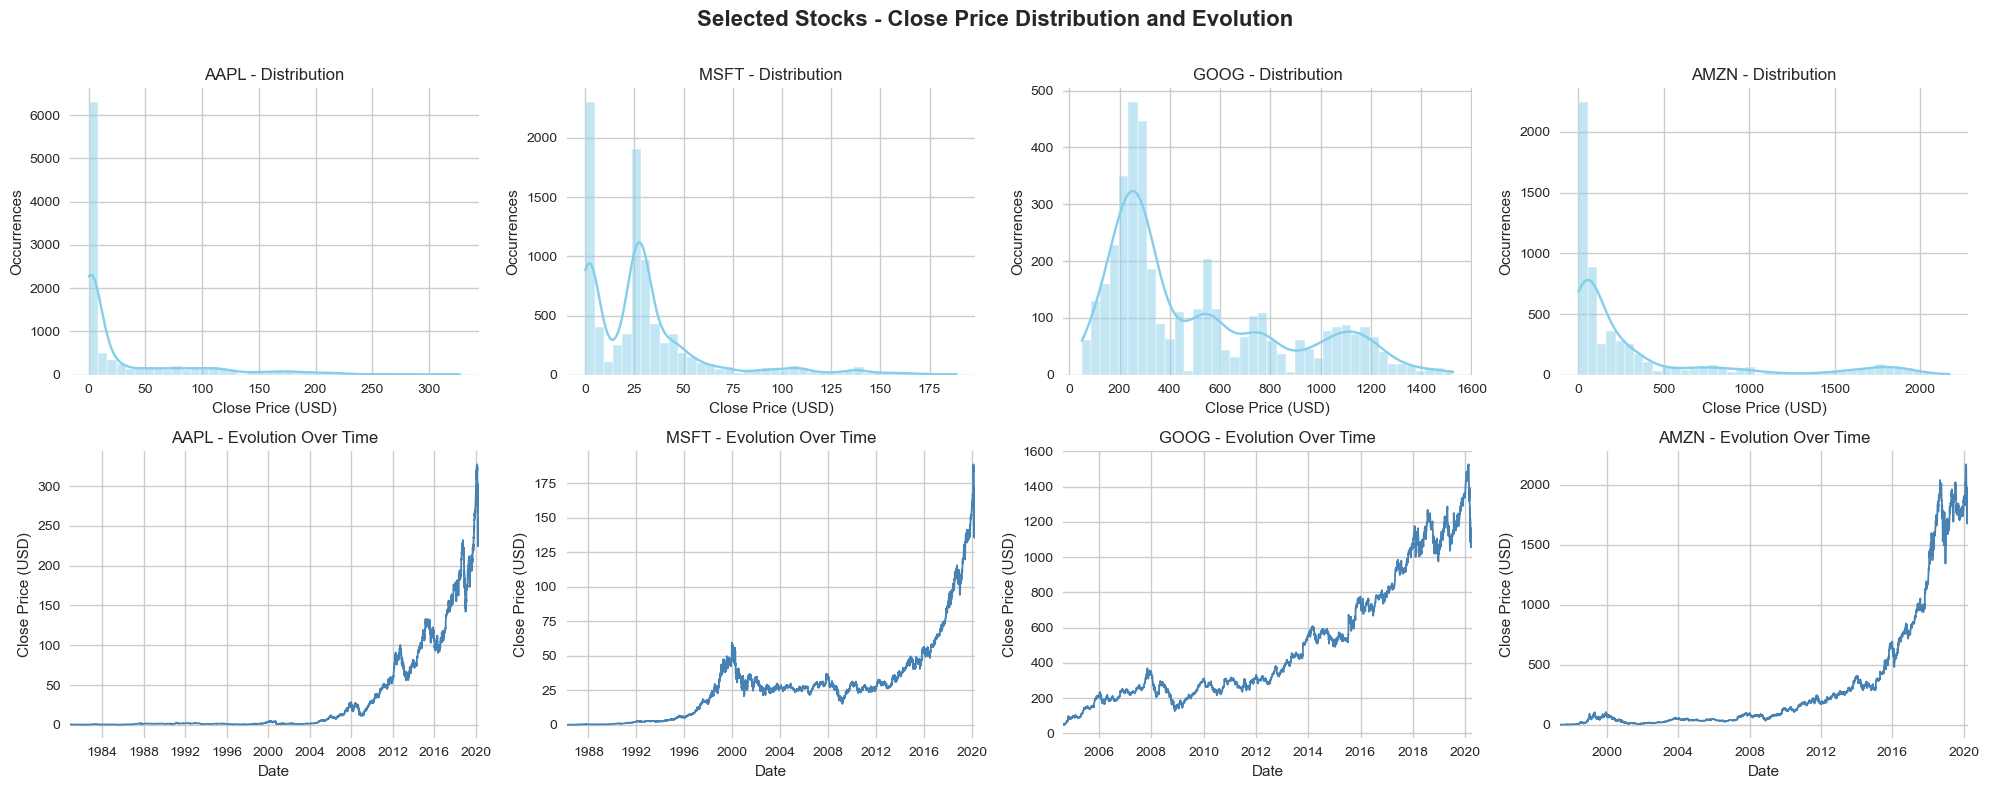

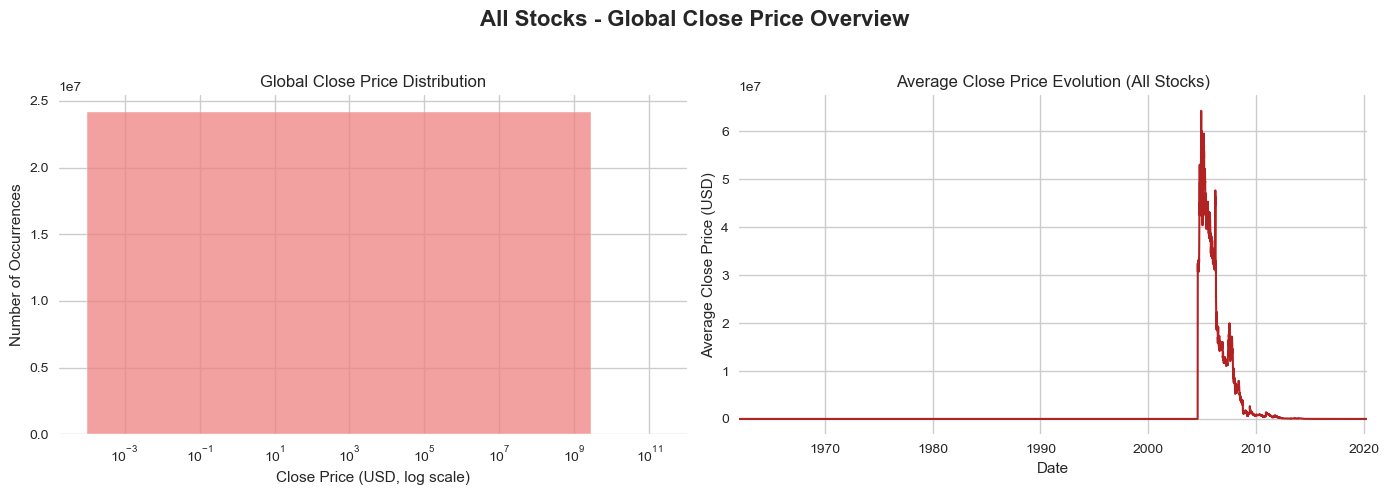

In [6]:
plot_raw_data_overview(stocks_raw, sample_stocks=["AAPL", "MSFT", "GOOG", "AMZN"], log_global=True)

The individual stock plots (e.g., AAPL, MSFT, GOOG, AMZN) reveal strongly right-skewed price distributions, where most daily closing prices are concentrated at lower values. This is typical of financial time series, as stock prices tend to grow multiplicatively rather than linearly. The temporal plots highlight long-term upward trends with distinct market corrections (e.g., around 2008 and 2020), illustrating both growth dynamics and periods of high volatility across companies.

At the aggregate level, the log-scaled global price distribution confirms a log-normal behavior, where many small-valued stocks coexist with a few extremely high-valued ones. The average price evolution over time, however, should be interpreted cautiously, since raw prices are not directly comparable across stocks and coverage varies historically.

**Missing values analysis**


Overall Statistics:
   • Total stocks analyzed: 5884
   • Stocks with missing values: 256
   • Stocks with no missing values: 5628
   • Average missing percentage: 0.02%
   • Max missing percentage: 52.57%

Top 10 stocks with most missing values:


,Stock,Total_Rows,Missing_Cells,Missing_Percentage
5757,WTRG,225,828,52.571429
4518,RILYP,2,6,42.857143
5860,ZIONO,150,144,13.714286
3719,NLOK,278,162,8.324769
4193,PIPR,134,66,7.036247
4546,RMI,175,54,4.408163
3814,NTR,1270,210,2.362205
2589,HTIA,80,6,1.071429
3429,MMX,313,18,0.821543
5635,VXX,554,24,0.618876


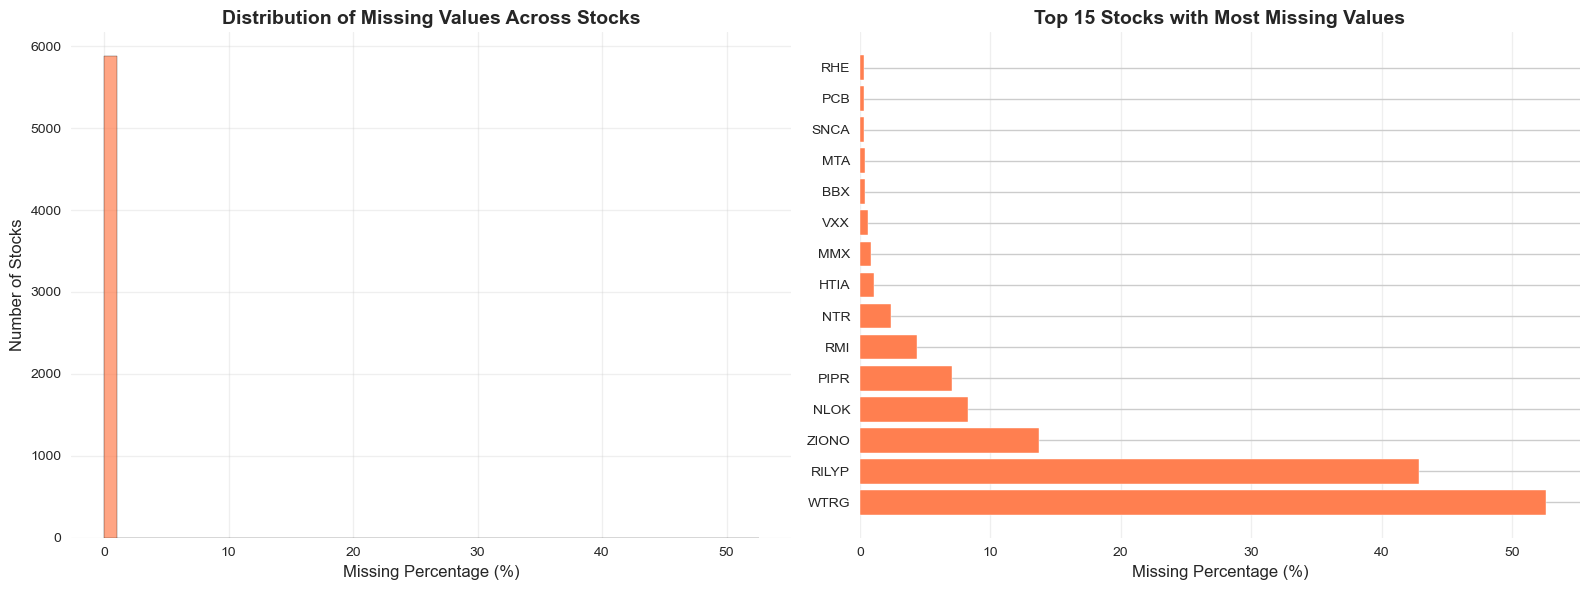

In [7]:
analyze_missing(stocks_raw)

Among the stocks with missing values, the top ten show varying degrees of incompleteness, ranging from over **50% missing cells for WTRG** to less than **1% for VXX**, indicating that only a few tickers suffer from severe data loss.


**Price correlation analyze**

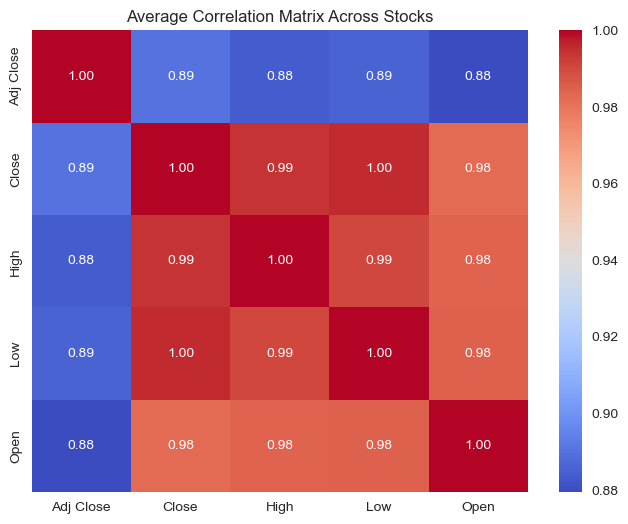

In [8]:
stocks_corr = analyze_correlations(stocks_raw)

This correlation analysis shows us the relation between the different features in the dataset. All prices features are well correlated apart from the adj close which is a bit less.

## 5. Data Filtering & Preprocessing

This section aims to transform the raw NASDAQ dataset into a clean and consistent version focused on company stocks between **1990 and 2020**. This step reduces the data volume, removes ETFs, and ensures temporal continuity across tickers.

The preprocessing pipeline is implemented in `/src/scripts/preprocess.py`,  
which defines modular functions to reproduce this step locally on the full dataset.  


### Overview of the Preprocessing Steps

| Step | Description | Output |
|------|--------------|---------|
| **1. Missing data handling** | Drop or impute missing price/volume values | Ensures valid time series |
| **2. Date filtering** | Keep records between 1990 and 2020 | Reduces dataset to recent decades |
| **3. Symbols filtering** | Keep only stocks symbols | Reduces dataset to stocks |

All transformations are non-destructive and reproducible via the same functions in `/src/scripts/preprocess.py`.


### Missing Data Handling

To ensure temporal continuity for future analyses such as volatility estimation, and because only a small portion of tickers present missing values (256 out of 5,884), all stocks with missing entries are currently removed from the dataset. In later stages of the project, we may explore imputation strategies to fill these few missing values instead.


In [9]:
# remove missing values
stocks_clean = clean_missing(stocks_raw)


Cleaned dataset: 5628 stocks remaining (removed 256 with NaNs)


### Date filtering
Filter the stock dataset to keep the 1990-2020 period

In [10]:
# Filter the dataset
stocks_period = filter_period(stocks_clean, start_year=1990, end_year=2020)
stocks_period['AAPL'].head()

Number of tickers in our period range: 5628


,Date,Open,High,Low,Close,Adj Close,Volume
2287,1990-01-02,1.258929,1.339286,1.250000,1.330357,1.078869,45799600
2288,1990-01-03,1.357143,1.357143,1.339286,1.339286,1.086111,51998800
2289,1990-01-04,1.366071,1.383929,1.330357,1.343750,1.089730,55378400
2290,1990-01-05,1.348214,1.366071,1.321429,1.348214,1.093350,30828000
2291,1990-01-08,1.339286,1.357143,1.321429,1.357143,1.100591,25393200


### Symbols filtering
Remove the symbols associated with ETFs

In [11]:
# keep only the symbols associated with stocks
symbols_stocks = symbols_raw[symbols_raw['ETF']=='N']
symbols_stocks.head()

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,...,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,...,N,NaN,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,...,N,NaN,AA,AA,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,...,N,N,NaN,AACG,N
5,Y,AAL,"American Airlines Group, Inc. - Common Stock",Q,Q,...,N,N,NaN,AAL,N
6,Y,AAMC,Altisource Asset Management Corp Com,A,,...,N,NaN,AAMC,AAMC,N


After preprocessing, the dataset contains approximately **5 600 active stock tickers**, with daily trading data covering three decades.  
This cleaned dataset forms the foundation for enrichment and aggregation steps.


## 6. Data Enrichment


### Sector Enrichment

Sector metadata is retrieved using the **Yahoo Finance API** through the `yfinance` package.  
The enrichment process is implemented in `/src/scripts/create_sector_mapping.py`.  
This script:
1. Iterates through all tickers in the cleaned dataset.  
2. Queries `yfinance.Ticker(ticker).info` to extract the *sector* field.  
3. Uses the `tqdm` progress bar for progress tracking.  
4. Saves the mapping into `data/symbol_sector_mapping_stocks.csv`.

Because this process is slow, the mapping is generated once locally and reused in all analyses.


### Sector mapping loading and analyze

In [12]:
# Load the generated symbol–sector mapping
sector_mapping = pd.read_csv("data/symbol_sector_mapping_stocks.csv")

# Display information about sectors mapping
summarize_sector_mapping(sector_mapping)


Total number of tickers: 5884

Number of known sectors: 11
List of sectors:
  - Basic Materials
  - Communication Services
  - Consumer Cyclical
  - Consumer Defensive
  - Energy
  - Financial Services
  - Healthcare
  - Industrials
  - Real Estate
  - Technology
  - Utilities

Number of stocks with unknown sector: 2140
Percentage unknown: 36.37%


### Sector Mapping Summary

| Metric | Value | Comment |
|---------|--------|---------|
| **Total tickers** | ~5 800 | Company stocks after filtering |
| **Mapped to sectors** | ≈ 64 % | Retrieved successfully via yfinance |
| **Unknown / unmapped** | ≈ 36 % | Typically delisted or unclassified |
| **Number of unique sectors** | 11 | Reflecting major industry groups |

Most tickers were successfully assigned to one of 11 major sectors.  
Tickers with missing sectors are labeled **"Unknown"** and can be excluded from aggregations.


### Clean sector mapping dataset
Remove Unknown sector

In [13]:
sector_mapping["Sector"] = sector_mapping["Sector"].replace(["Unknown", "nan", "NaN"], np.nan)
sector_mapping = sector_mapping.dropna(subset=["Sector"])

### Sector information addition to stocks dataset

In [14]:
# Merge mapping with cleaned dataset and sectors
stocks_with_sector, combined = add_sector_info(stocks_period, sector_mapping)

# list of all sectors name used later for the plots
sectors_name = combined['Sector'].unique()

# display an overview of the merged dataset
combined.head()

Number of tickers left after merge: 3540


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol,Sector
0,1999-11-18,32.546494,35.765381,28.612303,31.473534,27.068665,62546300,A,Healthcare
1,1999-11-19,30.713520,30.758226,28.478184,28.880543,24.838577,15234100,A,Healthcare
2,1999-11-22,29.551144,31.473534,28.657009,31.473534,27.068665,6577800,A,Healthcare
3,1999-11-23,30.400572,31.205294,28.612303,28.612303,24.607880,5975600,A,Healthcare
4,1999-11-24,28.701717,29.998211,28.612303,29.372318,25.261524,4843200,A,Healthcare


### Indicators computation
#### Return, Absolute Return, and Daily Volatility — Intuition and Relevance

To fully capture market dynamics, we use three complementary metrics that describe how prices evolve, how large their moves are, and how uncertain the market is. Further metrics could be add later if relevant for the next milestone.

---

##### Daily Return — *How much did it move?*

$$
r_{i,t} = \frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}}
$$

- **Meaning:** Measures the percentage change in price from one day to the next.  
- **Why it matters:**  
  - Normalizes price movements across different stock prices.  
  - Captures both direction and magnitude of change — essential for trend and performance analysis.  
  - Forms the basis for metrics like volatility, Sharpe ratio, and beta.
---

##### Absolute Return — *How large was the move, ignoring direction?*

$$
|r_{i,t}| = \left|\frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}}\right|
$$

- **Meaning:** Measures the magnitude of price change without considering if it was a gain or loss.  
- **Why it matters:**  
  - Highlights market activity and turbulence, regardless of trend direction.  
  - Serves as a simple volatility indicator when returns fluctuate strongly in either direction.  
  - Helps detect periods of elevated market risk (e.g., around macro events).
---

##### Daily Volatility Proxy — *How volatile was it within the day?*

$$
dv_{i,t} = \frac{High_{i,t} - Low_{i,t}}{Close_{i,t}}
$$

- **Meaning:** Quantifies the intraday price range relative to the closing price.  
- **Why it matters:**  
  - Acts as a proxy for intraday volatility when minute-level data are unavailable.  
  - Large values indicate strong disagreement or rapid reaction to market news.  
  - Complements daily returns by capturing within-day fluctuations.
---
This metric will be used later for **sector-level aggregation** and further analysis as they allows to ensure if the global event detection would be feasible or not.

### Indicator computation

In [15]:
# Compute indicators for all tickers that will be useful after aggregation
combined_with_return = add_columns(combined)
combined_with_return.head()

,Date,Open,High,Low,Close,...,Symbol,Sector,return,abs return,daily volatility
1,1999-11-19,30.713520,30.758226,28.478184,28.880543,...,A,Healthcare,-0.082386,0.082386,0.078947
2,1999-11-22,29.551144,31.473534,28.657009,31.473534,...,A,Healthcare,0.089783,0.089783,0.089489
3,1999-11-23,30.400572,31.205294,28.612303,28.612303,...,A,Healthcare,-0.090909,0.090909,0.090625
4,1999-11-24,28.701717,29.998211,28.612303,29.372318,...,A,Healthcare,0.026563,0.026563,0.047184
5,1999-11-26,29.238197,29.685265,29.148785,29.461731,...,A,Healthcare,0.003044,0.003044,0.018209


Computing those indicators it before aggregation ensures that sector-level indicators (mean return, volatility, etc.)  
are based on consistent stock-level transformations.


### Additional Note

We initially considered detecting and removing outliers in daily stock returns using the interquartile range (IQR) method, rather than applying this procedure to raw price data. Returns better capture the relative change in value and are more suitable for identifying abnormal price movements, since stock prices themselves are non-stationary and depend on long-term market trends.

However, during major financial events, such as the dot-com crash or the 2008 financial crisis, many stocks experienced sharp, yet genuine, fluctuations in returns. Applying an IQR-based outlier removal would have excluded a significant portion of data during these critical periods. Because these extreme values represent authentic market dynamics rather than data errors, we chose to preserve them to ensure that our analysis accurately reflects market behavior during periods of heightened volatility

## 7. Preliminary Aggregation

**Purpose:**  
Test the feasibility of sector-level aggregation by combining individual stock data into daily sector-level indicators.  
This step validates that the data structure supports grouped computations and helps identify which metrics will be most informative.


### Aggregation Logic — Sector-Level Indicators

The preliminary aggregation is implemented in `/src/scripts/preprocess.py`.  
For each **sector** \( s \) and **trading day** \( t \), we compute key metrics that summarize  
the collective behavior of all constituent stocks.

---

#### Average Close Price
$$
\overline{P}_{s,t} = \frac{1}{N_{s,t}} \sum_{i \in s} P_{i,t}
$$

- Represents the **typical price level** across all stocks in the sector.  
- Useful for tracking sector-wide trends and for visual comparisons between sectors.

---

#### Average Daily Return
$$
\overline{R}_{s,t} = \frac{1}{N_{s,t}} \sum_{i \in s} r_{i,t}
$$

- Measures the **average percentage change** of stocks in the sector.  
- Indicates whether the sector as a whole moved up or down on a given day.

---

#### Average Absolute Return
$$
\overline{|R|}_{s,t} = \frac{1}{N_{s,t}} \sum_{i \in s} |r_{i,t}|
$$

- Captures the **average magnitude of price changes**, ignoring direction.  
- Serves as a proxy for **market activity or turbulence** within the sector.  
- High values suggest that the sector is experiencing strong movements (in either direction).

---

#### Average Daily Volatility Proxy
$$
\overline{DV}_{s,t} = \frac{1}{N_{s,t}} \sum_{i \in s} \frac{High_{i,t} - Low_{i,t}}{Close_{i,t}}
$$

- Represents the **typical intraday price range** relative to the closing price.  
- Provides an indicator of **market uncertainty** or trading intensity.  
- Especially useful when minute-level data are unavailable.

---

#### Total Traded Volume
$$
V_{s,t}^{\text{total}} = \sum_{i \in s} Volume_{i,t}
$$

- Aggregates the **total number of shares traded** across the sector.  
- Reflects **market participation and liquidity** at the sector level.

---

#### Number of Stocks per Sector
$$
N_{s,t} = |\{ i \in s \text{ with data on day } t \}|
$$

- Represents the **breadth of available data** per sector.  
- Useful for assessing representativeness of sector averages (e.g., fewer stocks may reduce stability).

---
Together, these metrics provide a comprehensive daily overview of sector behavior, capturing trend (returns), intensity (absolute returns), uncertainty (volatility), and market participation (volume and count).

These metrics are preliminary and will be extended later mainly for inter-days analysis (e.g., inter-day volatility, rolling averages, correlation indicators).


### Aggregation of stocks by sector and date

In [16]:
# Aggregate by sector and date
sector_dfs = aggregate_by_sector(combined_with_return)

# save it
save_dict_of_dataframes(sector_dfs, folder="data/sector_data")


All 11 DataFrames saved in 'data/sector_data'.


The aggregation produces a compact time series per sector, each containing key indicators for every trading day.


### Example Output


In [17]:
# Example: View aggregated data for the "Technology" sector
sector_dfs['Technology'].head()

,Date,Avg_close,Avg_return,Avg_abs_return,Avg_daily_volatility,Total_Volume,Num_Stocks,Sector
0,1990-01-03,106.658818,0.005178,0.027432,0.045957,472714900,64,Technology
1,1990-01-04,105.234743,-0.002979,0.019457,0.032713,407947100,65,Technology
2,1990-01-05,103.726530,0.004097,0.021466,0.034979,223037200,66,Technology
3,1990-01-08,103.669732,-0.000923,0.017169,0.035132,186298700,66,Technology
4,1990-01-09,99.348979,-0.000107,0.019558,0.036969,292134000,65,Technology


This confirms that the aggregation step works as expected and can capture sector-level market dynamics.  
Subsequent analyses will refine the indicators and incorporate measures such as inter-day volatility and correlations.


### Load Preprocessed Data (Optional)

If you want to skip the preprocessing steps (sections 3-7) and start directly from the aggregated sector data, you can load the preprocessed data using the cell below. This is useful if you've already run the preprocessing pipeline once and saved the results.

In [18]:
# Load preprocessed sector data (uncomment to use)
# import os
# sector_dfs = {}
# sector_folder = "data/sector_data"
# for filename in os.listdir(sector_folder):
#     if filename.endswith('.csv'):
#         sector_name = filename.replace('.csv', '')
#         sector_dfs[sector_name] = pd.read_csv(os.path.join(sector_folder, filename))
# 
# # Get list of sector names
# sectors_name = list(sector_dfs.keys())
# print(f"Loaded {len(sector_dfs)} sectors: {sectors_name}")

## 8. Descriptive Checks on Aggregated Data

### What We Aim to Verify
The goal of this section is to ensure that the aggregated data behaves as expected.  
Possible checks include:

- Verifying that sector-level time series are continuous and complete.  
- Inspecting distributions of `avg_daily_volatility` and `num_stocks` across sectors.  
- Exploring temporal patterns or correlations between sectors.  
- Checking for visible reactions to major global events (e.g., 2000, 2008, 2020).  

These descriptive checks will help determine which indicators (returns, volumes, volatility, etc.) are most promising for deeper analysis.


### Note on Standardization and normalization
For the analysis and visualization of sector-level trends, we considered scaling stock data to improve comparability across stocks with different price levels. Standardization (centering data at zero and dividing by the standard deviation) and normalization (rescaling values to a fixed range, e.g., 0–1) can both facilitate visual comparisons of metrics such as returns, volatility, or average prices. However, applying these transformations to raw stock prices before aggregation could distort economically meaningful differences: high-priced stocks would be disproportionately affected, and extreme values during periods of high market volatility could be obscured. Therefore, we applied standardization or normalization only for plotting purposes, to improve readability and comparability of visualizations, while keeping the original data unscaled for all quantitative analyses and sector-level aggregations

In [19]:
# standardization of data in order to plot them
sectors_dfs_std = standardize_sector_dict(sector_dfs)

# Example: View aggregated data for the "Technology" sector
sectors_dfs_std['Technology'].head()

,Date,Avg_close,Avg_return,Avg_abs_return,Avg_daily_volatility,Total_Volume,Num_Stocks,Sector
0,1990-01-03,0.512895,-0.070136,-0.070215,0.017164,472714900,64,Technology
1,1990-01-04,0.487454,-0.070366,-0.070440,-0.810833,407947100,65,Technology
2,1990-01-05,0.460510,-0.070166,-0.070383,-0.669122,223037200,66,Technology
3,1990-01-08,0.459496,-0.070308,-0.070505,-0.659556,186298700,66,Technology
4,1990-01-09,0.382306,-0.070285,-0.070437,-0.544716,292134000,65,Technology


### Indicators plot per sectors

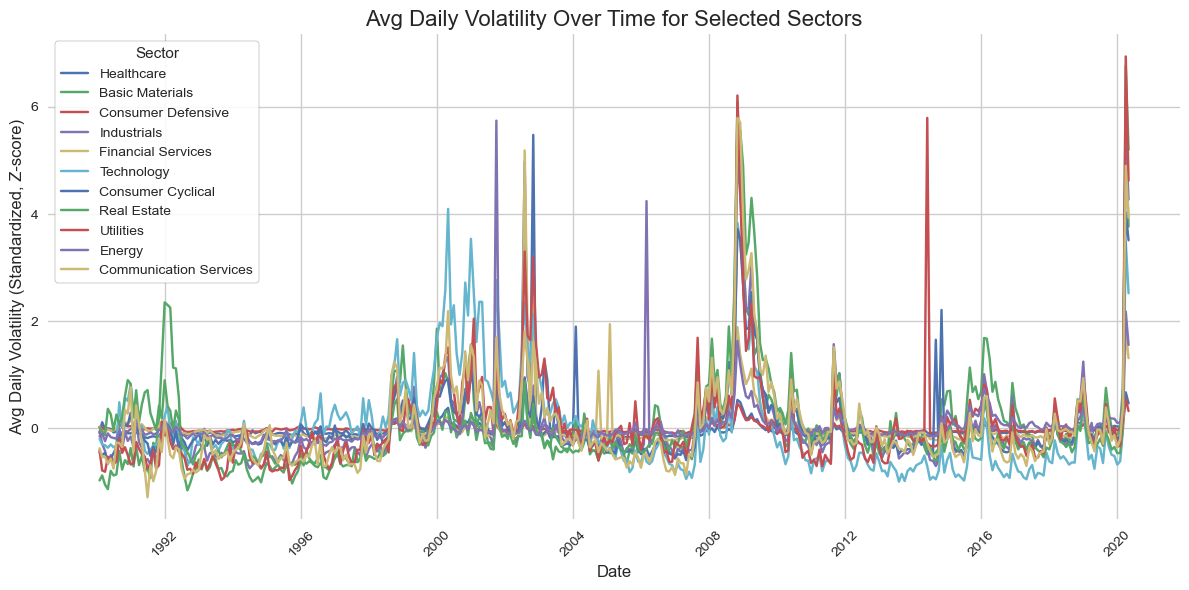

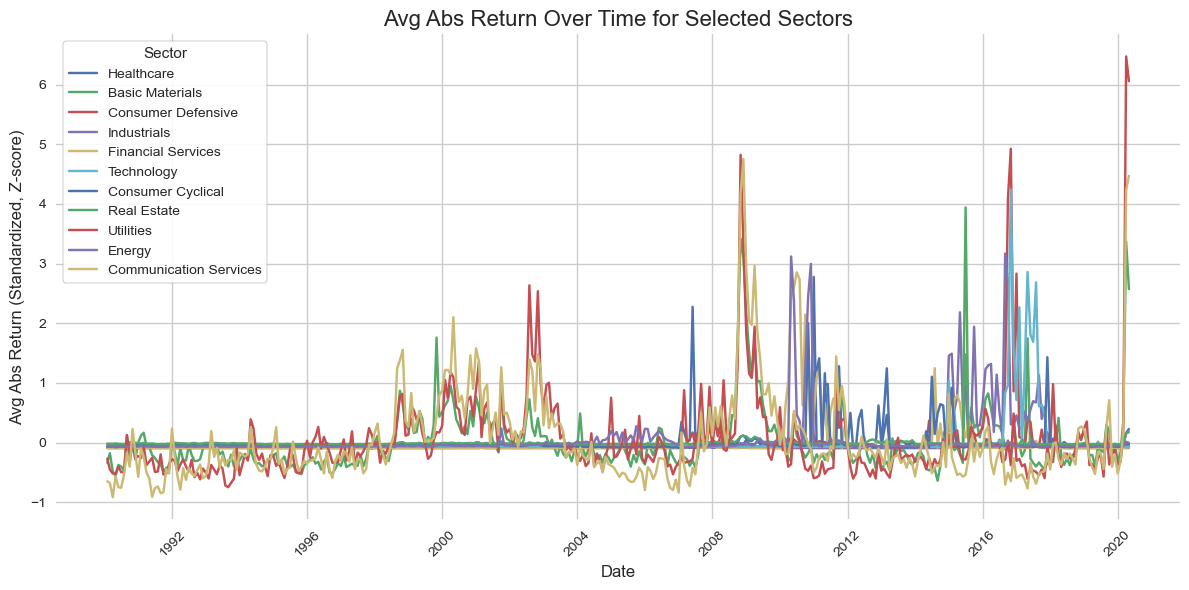

In [20]:
plot_sectors(sectors_dfs_std, sectors_name, column='Avg_daily_volatility', freq='ME', standardized=True)
plot_sectors(sectors_dfs_std, sectors_name, column='Avg_abs_return', freq='ME', standardized=True)

Both plots shows brutal change for some crisis events suchs as 2008 financial crisis or early covid. It will allows to detect crisis with further analysis.

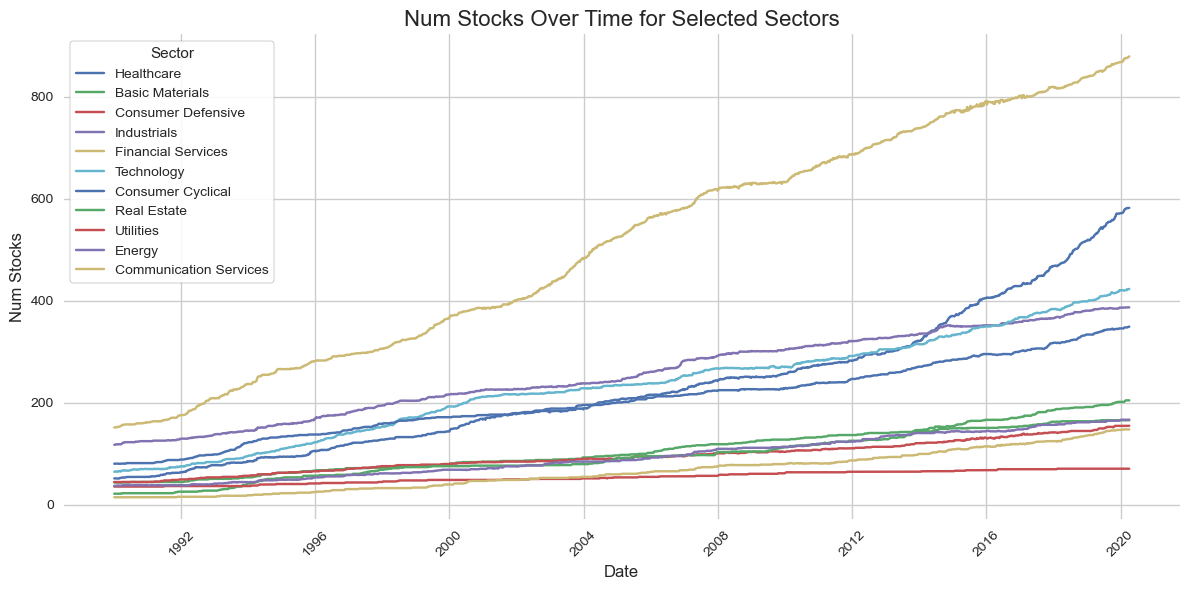

In [21]:
plot_sectors(sectors_dfs_std, sectors_name, column='Num_Stocks', freq='W', agg='mean')

This plots shows the evolution of number of stocks per sector, reflecting that some sectors might be more stable due to a bigger number of stocks. 

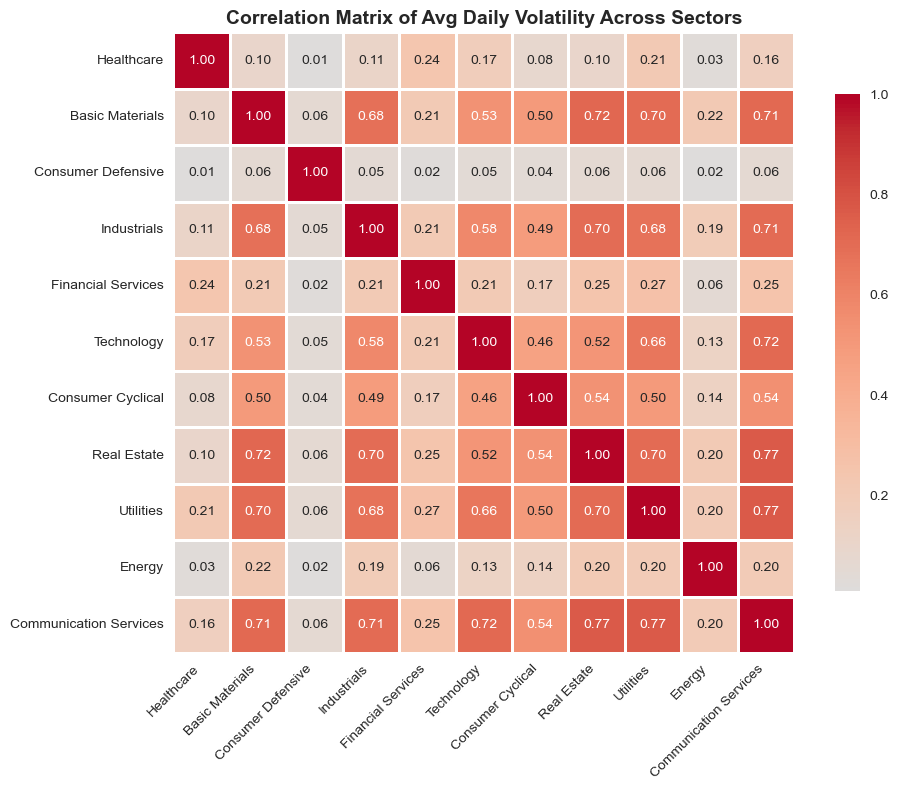

In [22]:
plot_sector_correlation(sector_dfs, sectors_name, column="Avg_daily_volatility")

The correlation of daily volatility across sectors allows us to see preliminary correlation (e.g. between Real Estate & Basic Materials)

These preliminary checks confirm that the aggregated dataset can be explored effectively at the sector level.  
In the next milestone, this section will be extended with richer visualizations and diagnostic statistics  
(such as inter-days volatility trends, inter-sector correlations, or network-based measures).


> ⚙️ *This section remains flexible and will evolve as we identify the most informative descriptive indicators.  
> Current checks are illustrative and serve to validate that the aggregated data is consistent and ready for deeper analysis.*


## 9. Analytical Roadmap

### Planned Analyses

The next phase of the project (Milestone 3) will expand from descriptive checks to analytical methods that quantify how sectors react to global events.  
Each planned analysis is supported by a methodological outline and essential mathematical details.

---

#### 1. Event Detection

We will identify abnormal market periods by measuring deviations in sector-level volatility and returns.  
Using rolling windows of size $w$, we will compute the rolling volatility:

$$
\sigma_{s,t}^{(w)} = \sqrt{\frac{1}{w} \sum_{k=0}^{w-1} (r_{s,t-k} - \bar{r}_{s,t}^{(w)})^2}
$$

where:  
- $r_{s,t}$ = return of sector $s$ at time $t$  
- $\bar{r}_{s,t}^{(w)}$ = mean return of sector $s$ over the window $w$  
- $\sigma_{s,t}^{(w)}$ = rolling volatility of sector $s$  

An **event** will be detected when volatility or return z-scores exceed a chosen threshold (e.g., $|z| > 2$).

---

#### 2. Sector Reaction Measurement

Once events are identified, we will measure how each sector reacts and recovers.  
Two core indicators will be computed:

- **Drawdown depth:**  

  $$
  D_{s,t} = \frac{P_{s,t} - \max\left(P_{s,\,[t-L,\,t]}\right)}{\max\left(P_{s,\,[t-L,\,t]}\right)}
  $$

  where:  
  - $P_{s,t}$ — price (or index level) of sector $s$ at time $t$  
  - $L$ — lookback period defining the pre-event window  
  - $D_{s,t}$ — percentage decline from the most recent local maximum
 

- **Recovery speed:**  
  Number of trading days required for $P_{s,t}$ or the mean return of sector $s$ to recover to pre-event levels.

These metrics will allow comparison of **leading** versus **lagging** sectors during crises and rebounds.

---

#### 3. Market Mood Indicator

We will build a synthetic indicator summarizing the collective behavior of the market —  
a weighted aggregation of standardized sector-level signals:

$$
M_t = \sum_{s} w_s \cdot z(r_{s,t})
$$

where:  
- $M_t$ = “Market Mood Index” at time $t$  
- $z(r_{s,t})$ = standardized return of sector $s$  
- $w_s$ = relative sector weight (e.g., based on traded volume or market cap)  

A negative $M_t$ will indicate broad market pessimism, while positive values will reflect overall optimism or recovery.

---

#### 4. Inter-Sector Correlations and Structure

We will analyze how sectors co-move and how correlation structures evolve over time using rolling correlations.

- **Rolling correlation matrix:**

$$
\rho_{s_1,s_2,t}^{(w)} =
\frac{\text{Cov}(r_{s_1,t-w:t},\, r_{s_2,t-w:t})}
{\sigma_{s_1,t}^{(w)} \sigma_{s_2,t}^{(w)}}
$$

   - where:  
      - $\rho_{s_1,s_2,t}^{(w)}$ = correlation between sectors $s_1$ and $s_2$ over window $w$  
      - $\text{Cov}(r_{s_1,t-w:t}, r_{s_2,t-w:t})$ = covariance of returns  
      - $\sigma_{s_1,t}^{(w)}$, $\sigma_{s_2,t}^{(w)}$ = rolling volatilities  

- **Network representation:**  
  Build a weighted network where nodes represent sectors and edge weights correspond to $|\rho_{s_1,s_2,t}^{(w)}|$.  
  During crises, correlations are expected to increase — resulting in network “tightening.”  

- **Clustering:**  
  Apply unsupervised learning (e.g., hierarchical clustering or community detection)  
  to group sectors with similar behaviors, revealing macroeconomic structures and regime shifts.

---

#### 5. Visualization and Interpretation

To communicate findings effectively, we will:

- Annotate volatility and return plots with major global events (e.g., dot-com bubble, 2008 crisis, COVID-19).  
- Visualize the **Market Mood Index** alongside sector-level trends.  
- Display the evolution of inter-sector networks to illustrate structural tightening and post-event relaxation.


---

### Methodological Notes
- Analytical formulas, rolling-window definitions, and detection thresholds will be detailed and implemented in Milestone 3.  
- The aggregated dataset already supports these operations efficiently due to its structure.  
- The methodology will balance statistical rigor (volatility-based signals) with interpretability and visualization quality.

---

> ⚙️ *This roadmap summarizes the planned next steps.  
> The exact analytical methods and visualizations may evolve based on insights from further exploratory work.*


## 10. Discussion & Reproducibility


### Summary of Progress

- The **NASDAQ dataset** (1960–2020) has been successfully accessed and understood through `exploration.ipynb`.  
- A modular **data pipeline** was implemented:  
  - Cleaning and filtering to stocks (1990–2020).  
  - Enrichment with sector metadata via `yfinance` + `tqdm`.  
  - Computation of market indicators.  
  - Preliminary aggregation at the sector level.  
- Light **descriptive checks** confirmed the data’s internal consistency and analytical potential.  
- A clear **analytical roadmap** has been outlined for Milestone 3.

---

### Current Limitations and Next Steps

| Aspect | Current Status | Planned Improvement |
|--------|----------------|--------------------|
| **Outliers** | No outliers were removed | Try to difference outliers from extreme-crisis values |
| **Indicators** | Only daily indicators tested | Add inter-days volatility, correlation, and network-based metrics |
| **Event detection** | Not yet implemented | Introduce rolling z-scores and threshold-based detection |
| **Visualization** | Minimal checks | Develop richer, event-annotated plots |
| **Sector coverage** | Only ~64 % of stocks mapped | Review “Unknown” tickers, assess impact |

The pipeline is stable, but further experimentation with analytical metrics and visualization choices will follow in Milestone 3.


## 11. References


### 📊 Data Sources
- **NASDAQ Historical Data (1960–2020)** — *Jackson Crow*, Kaggle  
  <https://www.kaggle.com/datasets/jacksoncrow/stock-market-dataset>  
- **Sector Metadata:** *Yahoo Finance API* accessed through the `yfinance` Python package.  

---

### 🧰 Tools and Libraries
- **pandas**, **numpy**, **sklearn** — data manipulation and numerical computation  
- **matplotlib**, **seaborn** — data visualization  
- **tqdm** — progress tracking during API queries  
- **yfinance** — retrieval of financial metadata  
- **Python 3.10+**, **Jupyter Notebook** — development environment  

---

### 📁 Project Structure and Resources
- Full project description and methodology: [`README.md`](../README.md)  
- Data pipeline and aggregation logic: [`/src/`](../src/) directory  
- Notebook structure, and function design were assisted by LLMs

---

> 🧩 *All external resources are open-access and used for academic, non-commercial purposes  
> within the EPFL Applied Data Analysis (ADA 2025) course.*
